In [27]:
# ─────────────────────────────────────────────────────────────────────────────
# porosity_field_model.ipynb
#
# A trainable spatial porosity prediction model built on size-filtered CT data.
#
# Spatial coordinates are learned in plate-normalised space [0,1]×[0,1]:
#   x_norm = x_mm / plate_width_mm,   y_norm = y_mm / plate_height_mm
# Training samples are centred in both plate dimensions so the central sample
# sits at (0.5, 0.5) in plate-fraction space.
#
# At prediction time any query (x_mm, y_mm) is normalised by the target plate
# dimensions before querying the RBF, making the learned pattern size-invariant
# and preventing unbounded extrapolation into unsampled mm regions.
#
# Workflow:
#   1. Configure training datasets (Cell 2).
#   2. Set model options and call model.fit() (Cell 2).
#   3. Supply target build-plate dimensions and process parameters (Cell 3).
#
# API surface (PorosityPatternModel):
#   model.add_dataset(ds)                            → add a training dataset
#   model.fit()                                      → train the spatial model
#   model.predict(x_mm, y_mm,
#                 plate_width_mm, plate_height_mm,
#                 mean_porosity)                     → single-point prediction (%)
#   model.predict_grid(width_mm, height_mm,
#                      mean_porosity,
#                      resolution_mm)                → DataFrame over full plate
#   model.plot_training_field(...)                   → pattern in normalised space
#   model.plot_predicted_field(width_mm, height_mm,
#                              mean_porosity, ...)    → continuous mm heatmap
# ─────────────────────────────────────────────────────────────────────────────
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from scipy.interpolate import RBFInterpolator
from typing import List, Optional, Tuple


# ══════════════════════════════════════════════════════════════════════════════
# DATA LOADER
# ══════════════════════════════════════════════════════════════════════════════

class SizeFilteredPorosityDataset:
    """
    Loads overall_porosity_pct and converts grid indices to plate-normalised
    coordinates [0,1]×[0,1].

    Each sample array is centred in both plate dimensions so the middle sample
    sits at (plate_width_mm/2, plate_height_mm/2):

        x_data_span = (n_cols - 1) * core_pitch_mm
        x_offset    = plate_width_mm  / 2 - x_data_span / 2
        x_mm        = col * core_pitch_mm + x_offset

        y_data_span = (n_rows - 1) * core_pitch_mm
        y_offset    = plate_height_mm / 2 - y_data_span / 2
        y_mm        = row * core_pitch_mm + y_offset

    Normalised coordinates (stored as points_norm, used for RBF fitting):
        x_norm = x_mm / plate_width_mm
        y_norm = y_mm / plate_height_mm
    """

    def __init__(self, title: str, base_dir: str, folder_prefix: str,
                 ignore_indices, start_idx: int, cols: int, index_pattern,
                 core_pitch_mm:   float = 6.0,
                 plate_width_mm:  float = 120.0,
                 plate_height_mm: float = 120.0):
        self.title           = title
        self.base_dir        = Path(base_dir)
        self.folder_prefix   = folder_prefix
        self.ignore_indices  = set(ignore_indices)
        self.start_idx       = start_idx
        self.cols            = cols
        self.index_pattern   = index_pattern
        self.core_pitch_mm   = core_pitch_mm
        self.plate_width_mm  = plate_width_mm
        self.plate_height_mm = plate_height_mm

        self.df_clean:    Optional[pd.DataFrame] = None
        self.points:      Optional[np.ndarray]   = None  # (N,2) — x_mm, y_mm
        self.points_norm: Optional[np.ndarray]   = None  # (N,2) — x_norm, y_norm ∈ [0,1]
        self.values:      Optional[np.ndarray]   = None  # (N,)  — porosity %

    def _iter_folders(self):
        for folder in sorted(self.base_dir.iterdir()):
            if not (folder.is_dir() and
                    folder.name.lower().startswith(self.folder_prefix.lower())):
                continue
            m = self.index_pattern.search(folder.name)
            if not m:
                continue
            idx = int(m.group(1))
            if idx not in self.ignore_indices:
                yield idx, folder

    def load_data(self) -> 'SizeFilteredPorosityDataset':
        data = []
        for idx, folder in self._iter_folders():
            csv = folder / 'core_porosity_summary_minDiam50um.csv'
            if not csv.exists():
                continue
            df_s = pd.read_csv(csv, header=None, index_col=0)
            try:
                pct = float(df_s.loc['overall_porosity_pct', 1])
            except (KeyError, ValueError):
                continue
            data.append({'index': idx, 'value': pct})

        df = pd.DataFrame(data).sort_values('index')
        df['col'] = (df['index'] - self.start_idx) % self.cols
        df['row'] = (df['index'] - self.start_idx) // self.cols

        # centre the sample array in both plate dimensions
        n_cols      = df['col'].max() + 1
        n_rows      = df['row'].max() + 1
        x_data_span = (n_cols - 1) * self.core_pitch_mm
        y_data_span = (n_rows - 1) * self.core_pitch_mm
        x_offset    = self.plate_width_mm  / 2 - x_data_span / 2
        y_offset    = self.plate_height_mm / 2 - y_data_span / 2
        df['x_mm']  = df['col'] * self.core_pitch_mm + x_offset
        df['y_mm']  = df['row'] * self.core_pitch_mm + y_offset

        self.df_clean    = df.dropna(subset=['value']).copy()
        self.points      = self.df_clean[['x_mm', 'y_mm']].to_numpy(dtype=float)
        self.points_norm = self.points / np.array([self.plate_width_mm,
                                                    self.plate_height_mm])
        self.values      = self.df_clean['value'].to_numpy(dtype=float)

        x0, x1   = self.points[:, 0].min(), self.points[:, 0].max()
        y0, y1   = self.points[:, 1].min(), self.points[:, 1].max()
        xn0, xn1 = self.points_norm[:, 0].min(), self.points_norm[:, 0].max()
        yn0, yn1 = self.points_norm[:, 1].min(), self.points_norm[:, 1].max()
        print(f"  [{self.title}]")
        print(f"    n={len(self.values)}  "
              f"μ={self.values.mean():.4f}%  σ={self.values.std():.4f}%")
        print(f"    x: {x0:.1f}–{x1:.1f} mm  "
              f"(norm {xn0:.3f}–{xn1:.3f}, centre {(xn0+xn1)/2:.3f})")
        print(f"    y: {y0:.1f}–{y1:.1f} mm  "
              f"(norm {yn0:.3f}–{yn1:.3f}, centre {(yn0+yn1)/2:.3f})")
        return self


# ══════════════════════════════════════════════════════════════════════════════
# MODEL
# ══════════════════════════════════════════════════════════════════════════════

class PorosityPatternModel:
    """
    Learns the spatial porosity pattern from historical CT datasets and predicts
    local porosity for a new build plate / process condition.

    Coordinates are normalised to [0,1]×[0,1] relative to each training plate's
    dimensions before fitting. At predict time, the query point is normalised by
    the target plate dimensions — making the pattern size-invariant.

    Scaling options
    ───────────────
    'z_score'  — each dataset centred (μ=0, σ=1) before merging.
                 Prediction: mean + z * std  (std defaults to pooled training std).

    'relative' — each dataset divided by its own mean; model predicts a spatial
                 multiplier (1.0 = exactly average).
                 Prediction: mean_porosity × multiplier.
                 Best choice for cross-process generalisation.

    'min_max'  — each dataset scaled to [0, 1].
                 Prediction: mean + (value − 0.5) × 2 × std.

    'absolute' — raw % values merged with no scaling; mean_porosity unused.

    RBF smoothing guide  (normalised coordinates in [0,1]×[0,1])
    ──────────────────────────────────────────────────────────────
    Coordinates are plate fractions, so adjacent-sample distance ≈ pitch/plate.
    For a 120 mm plate at 6 mm pitch that is ≈ 0.05, and thin-plate-spline
    kernel values r²·log(r) are small (<0.01) at that scale — the smoothing
    range is therefore very different from mm-space fitting.

    0          → exact interpolation (averages duplicate positions)
    0.001–0.01 → light smoothing; closely follows training samples
    0.01–0.1   → moderate smoothing; recommended starting point (default 0.02)
    >0.5       → heavy smoothing; approaches a broad polynomial trend
    """

    VALID_SCALINGS = ('z_score', 'relative', 'min_max', 'absolute')

    def __init__(self,
                 scaling:      str   = 'z_score',
                 smoothing:    float = 0.02,
                 homogenize_x: bool  = False):
        if scaling not in self.VALID_SCALINGS:
            raise ValueError(f"scaling must be one of {self.VALID_SCALINGS}")
        self.scaling      = scaling
        self.smoothing    = smoothing
        self.homogenize_x = homogenize_x

        self._datasets:           List[SizeFilteredPorosityDataset] = []
        self._merged_points:      Optional[np.ndarray] = None  # mm — for info / display
        self._merged_points_norm: Optional[np.ndarray] = None  # [0,1] — used by RBF
        self._merged_values:      Optional[np.ndarray] = None
        self._model_2d:           Optional[RBFInterpolator] = None
        self._model_1d:           Optional[RBFInterpolator] = None  # X-homogenized
        self._pooled_mean:        Optional[float] = None
        self._pooled_std:         Optional[float] = None
        self._is_fitted:          bool = False

    # ── Public API ─────────────────────────────────────────────────────────────

    def add_dataset(self, ds: SizeFilteredPorosityDataset) -> 'PorosityPatternModel':
        """Append a training dataset; returns self for chaining."""
        self._datasets.append(ds)
        return self

    def fit(self) -> 'PorosityPatternModel':
        """Load data (if needed), scale, merge, and fit both RBF models."""
        if not self._datasets:
            raise ValueError("No datasets added. Call add_dataset() first.")

        print(f"PorosityPatternModel.fit()")
        print(f"  scaling={self.scaling!r}  smoothing={self.smoothing}"
              f"  homogenize_x={self.homogenize_x}")
        print("-" * 60)

        for ds in self._datasets:
            if ds.points is None:
                ds.load_data()

        pts_list, pts_norm_list, scaled_list, raw_list = [], [], [], []
        for ds in self._datasets:
            pts_list.append(ds.points.copy())
            pts_norm_list.append(ds.points_norm.copy())
            scaled_list.append(self._scale(ds.values))
            raw_list.append(ds.values.copy())

        self._merged_points      = np.vstack(pts_list)
        self._merged_points_norm = np.vstack(pts_norm_list)
        self._merged_values      = np.concatenate(scaled_list)
        raw_all                  = np.concatenate(raw_list)
        self._pooled_mean        = float(raw_all.mean())
        self._pooled_std         = float(raw_all.std())

        # average duplicate normalised positions — required when smoothing=0
        df_dedup = (pd.DataFrame(
                        np.column_stack([self._merged_points_norm, self._merged_values]),
                        columns=['x', 'y', 'val'])
                    .groupby(['x', 'y'], as_index=False).mean())
        fit_pts = df_dedup[['x', 'y']].to_numpy()   # normalised [0,1]
        fit_val = df_dedup['val'].to_numpy()
        n_dupes = len(self._merged_points_norm) - len(fit_pts)
        if n_dupes:
            print(f"  ({n_dupes} duplicate normalised position(s) averaged before RBF fit)")

        self._model_2d = RBFInterpolator(
            fit_pts, fit_val,
            kernel='thin_plate_spline', smoothing=self.smoothing)

        # 1D X-homogenized: row averages in normalised y, then 1D RBF
        df_h = (pd.DataFrame({'y': fit_pts[:, 1], 'val': fit_val})
                .groupby('y', as_index=False).mean())
        self._model_1d = RBFInterpolator(
            df_h['y'].to_numpy()[:, None], df_h['val'].to_numpy(),
            kernel='thin_plate_spline', smoothing=self.smoothing)

        self._is_fitted = True
        pn = fit_pts
        print(f"\nFitted on {len(pn)} unique normalised positions "
              f"({len(self._merged_points_norm)} total from {len(self._datasets)} dataset(s)).")
        print(f"Training coverage (plate fraction): "
              f"x={pn[:,0].min():.3f}–{pn[:,0].max():.3f}  "
              f"y={pn[:,1].min():.3f}–{pn[:,1].max():.3f}")
        print(f"Pooled stats:  μ={self._pooled_mean:.4f}%  σ={self._pooled_std:.4f}%")
        return self

    def predict(self,
                x_mm:            float,
                y_mm:            float,
                plate_width_mm:  float,
                plate_height_mm: float,
                mean_porosity:   float,
                std_porosity:    Optional[float] = None) -> float:
        """
        Predict local porosity (%) at a physical mm coordinate on a target plate.

        Parameters
        ----------
        x_mm, y_mm           : position on the target build plate (mm)
        plate_width_mm       : target plate X dimension (mm)
        plate_height_mm      : target plate Y dimension (mm)
        mean_porosity        : expected overall porosity % for the new process
        std_porosity         : expected std % (z_score/min_max; defaults to pooled std)
        """
        self._check_fitted()
        x_n = x_mm / plate_width_mm
        y_n = y_mm / plate_height_mm
        if self.homogenize_x:
            raw = float(self._model_1d(np.array([[y_n]])))
        else:
            raw = float(self._model_2d(np.array([[x_n, y_n]])))
        return float(self._denorm(raw, mean_porosity, std_porosity))

    def predict_grid(self,
                     width_mm:      float,
                     height_mm:     float,
                     mean_porosity: float,
                     std_porosity:  Optional[float] = None,
                     resolution_mm: float           = 1.0) -> pd.DataFrame:
        """
        Predict porosity on a regular mm grid covering the target build plate.

        Parameters
        ----------
        width_mm, height_mm : build plate dimensions in mm
        mean_porosity       : expected overall porosity %
        std_porosity        : expected std % (defaults to pooled training std)
        resolution_mm       : grid spacing in mm (default 1 mm)

        Returns
        -------
        DataFrame with columns x_mm, y_mm, predicted_porosity_pct
        """
        self._check_fitted()
        xs = np.arange(0, width_mm  + resolution_mm * 0.5, resolution_mm)
        ys = np.arange(0, height_mm + resolution_mm * 0.5, resolution_mm)
        gx, gy = np.meshgrid(xs, ys)
        gx_n   = gx / width_mm
        gy_n   = gy / height_mm

        if self.homogenize_x:
            raw_flat = self._model_1d(gy_n.ravel()[:, None]).ravel()
        else:
            raw_flat = self._model_2d(
                np.column_stack((gx_n.ravel(), gy_n.ravel()))).ravel()

        pred_flat = np.array([self._denorm(v, mean_porosity, std_porosity)
                               for v in raw_flat])
        return pd.DataFrame({'x_mm': gx.ravel(), 'y_mm': gy.ravel(),
                              'predicted_porosity_pct': pred_flat})

    def plot_training_field(self,
                            save_dir:     Optional[str]  = None,
                            homogenize_x: Optional[bool] = None,
                            n_grid:       int            = 300):
        """
        Visualise the learned spatial pattern in normalised [0,1]×[0,1] space.

        Parameters
        ----------
        save_dir     : directory for PNG output (created if needed)
        homogenize_x : override per-call (None = use model default)
        n_grid       : grid resolution along each normalised axis (default 300)
        """
        self._check_fitted()
        hx = self.homogenize_x if homogenize_x is None else homogenize_x

        pn = self._merged_points_norm
        x0, x1 = pn[:, 0].min(), pn[:, 0].max()
        y0, y1 = pn[:, 1].min(), pn[:, 1].max()

        xs = np.linspace(x0, x1, max(2, n_grid))
        ys = np.linspace(y0, y1, max(2, n_grid))
        gx, gy = np.meshgrid(xs, ys)

        if hx:
            grid_z  = self._model_1d(gy.ravel()[:, None]).reshape(gy.shape)
            x_label = "X (plate fraction) — ignored"
            t_extra = " — X Homogenized"
        else:
            grid_z  = self._model_2d(
                np.column_stack((gx.ravel(), gy.ravel()))).reshape(gy.shape)
            x_label = "X (plate fraction)"
            t_extra = ""

        cbar_label, cmap, vmin, vmax = self._cmap_params(grid_z)

        aspect = (x1 - x0) / max(y1 - y0, 1e-6)
        fig, ax = plt.subplots(figsize=(max(5, aspect * 8), 8))
        im = ax.pcolormesh(gx, gy, grid_z, shading='auto',
                           cmap=cmap, vmin=vmin, vmax=vmax)

        markers = ['o', '+', '^', 's']
        for i, src in enumerate(self._datasets):
            mk = markers[i % len(markers)]
            kw = dict(marker=mk, s=100, linewidths=1.5, label=src.title)
            if mk == 'o':
                ax.scatter(src.points_norm[:, 0], src.points_norm[:, 1],
                           edgecolors='black', facecolors='none', **kw)
            else:
                ax.scatter(src.points_norm[:, 0], src.points_norm[:, 1],
                           color='black', **kw)

        plt.colorbar(im, ax=ax, label=cbar_label)
        ax.set_title(f"Training Spatial Pattern{t_extra}\n"
                     f"(normalised coordinates — plate fraction)\n"
                     f"scaling={self.scaling}  |  smoothing={self.smoothing}",
                     fontsize=14, pad=15)
        ax.set_xlabel(x_label, fontsize=12)
        ax.set_ylabel("Y (plate fraction)", fontsize=12)
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
        ax.invert_yaxis()
        ax.set_aspect('equal')
        plt.tight_layout()

        if save_dir:
            Path(save_dir).mkdir(parents=True, exist_ok=True)
            hx_tag = "_homX" if hx else ""
            out = (Path(save_dir) /
                   f"training_pattern_{self.scaling}_smooth{self.smoothing}{hx_tag}.png")
            plt.savefig(out, dpi=300)
            print(f"Saved: {out}")
        plt.show()

    def plot_predicted_field(self,
                             width_mm:       float,
                             height_mm:      float,
                             mean_porosity:  float,
                             std_porosity:   Optional[float]                    = None,
                             resolution_mm:  float                              = 1.0,
                             save_dir:       Optional[str]                      = None,
                             homogenize_x:   Optional[bool]                     = None,
                             show_training:  bool                               = False,
                             sample_regions: Optional[List[Tuple[float, ...]]]  = None,
                             title_extra:    str                                = ""):
        """
        Continuous mm heatmap of predicted porosity over a target build plate.

        Parameters
        ----------
        width_mm, height_mm : build plate dimensions in mm
        mean_porosity       : expected overall porosity %
        std_porosity        : expected std % (defaults to pooled training std)
        resolution_mm       : prediction grid spacing (default 1 mm)
        save_dir            : directory for PNG output (created if needed)
        homogenize_x        : override per-call (None = use model default)
        show_training       : overlay projected training sample locations
        sample_regions      : list of (x_center_mm, y_center_mm[, width_mm,
                              height_mm[, label]]) — each entry draws a labelled
                              rectangle and appends region statistics at the
                              bottom of the figure; width/height default to 6×6 mm
        title_extra         : extra line in plot title (e.g. process name)
        """
        self._check_fitted()
        hx  = self.homogenize_x if homogenize_x is None else homogenize_x
        std = std_porosity if std_porosity is not None else self._pooled_std

        xs = np.arange(0, width_mm  + resolution_mm * 0.5, resolution_mm)
        ys = np.arange(0, height_mm + resolution_mm * 0.5, resolution_mm)
        gx, gy = np.meshgrid(xs, ys)
        gx_n   = gx / width_mm
        gy_n   = gy / height_mm

        if hx:
            raw_grid = self._model_1d(gy_n.ravel()[:, None]).reshape(gy.shape)
            x_label  = "X (mm) — ignored"
            t_suffix = " — X Homogenized"
        else:
            raw_grid = self._model_2d(
                np.column_stack((gx_n.ravel(), gy_n.ravel()))).reshape(gy.shape)
            x_label  = "X (mm)"
            t_suffix = ""

        pred = np.vectorize(lambda v: self._denorm(v, mean_porosity, std))(raw_grid)

        aspect = width_mm / max(height_mm, 1)
        fig, ax = plt.subplots(figsize=(max(5, aspect * 8), 8))
        im = ax.pcolormesh(gx, gy, pred, shading='auto', cmap='YlGnBu')

        if show_training:
            markers = ['o', '+', '^', 's']
            for i, src in enumerate(self._datasets):
                mk = markers[i % len(markers)]
                x_plot = src.points_norm[:, 0] * width_mm
                y_plot = src.points_norm[:, 1] * height_mm
                kw = dict(marker=mk, s=60, linewidths=1.2,
                          label=src.title, zorder=3)
                if mk == 'o':
                    ax.scatter(x_plot, y_plot,
                               edgecolors='white', facecolors='none', **kw)
                else:
                    ax.scatter(x_plot, y_plot, color='white', **kw)
            ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2,
                      fontsize=9)

        _COLORS = ['#e6194b', '#3cb44b', '#4363d8', '#f58231',
                   '#911eb4', '#42d4f4', '#f032e6', '#bfef45']

        all_stats = []
        if sample_regions:
            for i, region in enumerate(sample_regions):
                cx, cy = region[0], region[1]
                sw     = region[2] if len(region) > 2 else 6.0
                sh     = region[3] if len(region) > 3 else 6.0
                label  = region[4] if len(region) > 4 else f"Region {i + 1}"
                color  = _COLORS[i % len(_COLORS)]

                rect = mpatches.Rectangle(
                    (cx - sw / 2, cy - sh / 2), sw, sh,
                    linewidth=2, edgecolor=color, facecolor='none',
                    linestyle='--', zorder=4)
                ax.add_patch(rect)
                ax.plot(cx, cy, marker='+', color=color, markersize=12,
                        markeredgewidth=2, zorder=5, linestyle='none')
                # label at top-left corner, floating above the rectangle edge
                ax.text(cx - sw / 2, cy - sh / 2, label,
                        color=color, fontsize=9, ha='left', va='bottom',
                        fontweight='bold', zorder=6,
                        bbox=dict(facecolor='white', alpha=0.55,
                                  edgecolor='none', pad=1))

                mask = ((gx >= cx - sw / 2) & (gx <= cx + sw / 2) &
                        (gy >= cy - sh / 2) & (gy <= cy + sh / 2))
                region_vals = pred[mask]
                if region_vals.size > 0:
                    all_stats.append((
                        label, color, sw, sh, cx, cy,
                        float(region_vals.mean()),
                        float(region_vals.min()),
                        float(region_vals.max()),
                    ))

        plt.colorbar(im, ax=ax, label="Predicted Porosity %")

        scale_note = (f"std={std:.4f}%" if self.scaling == 'z_score'
                      else f"scaling={self.scaling}")
        ax.set_title(
            f"Predicted Porosity Field{t_suffix}"
            + (f"\n{title_extra}" if title_extra else "") +
            f"\nmean={mean_porosity:.4f}%  |  {scale_note}"
            f"  |  smooth={self.smoothing}",
            fontsize=13, pad=15)
        ax.set_xlabel(x_label, fontsize=12)
        ax.set_ylabel("Y (mm)", fontsize=12)
        ax.set_xlim(0, width_mm)
        ax.set_ylim(0, height_mm)
        ax.invert_yaxis()
        ax.set_aspect('equal')

        if all_stats:
            lh  = 0.042   # figure-fraction height per stats line
            bot = 0.01 + len(all_stats) * lh
            plt.tight_layout(rect=[0, bot, 1, 1])
            for j, (label, color, sw, sh, cx, cy, r_mean, r_min, r_max) in \
                    enumerate(all_stats):
                txt = (f"{label}  ({sw:.1f}×{sh:.1f} mm @ {cx:.1f}, {cy:.1f} mm)  "
                       f"mean = {r_mean:.4f}%    min = {r_min:.4f}%    "
                       f"max = {r_max:.4f}%")
                y_pos = 0.01 + (len(all_stats) - 1 - j) * lh
                fig.text(0.5, y_pos, txt, ha='center', va='bottom',
                         fontsize=9.5, color=color,
                         bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                                   edgecolor=color, alpha=0.9))
        else:
            plt.tight_layout()

        if save_dir:
            Path(save_dir).mkdir(parents=True, exist_ok=True)
            hx_tag = "_homX" if hx else ""
            fname  = (f"predicted_{width_mm:.0f}x{height_mm:.0f}mm"
                      f"_mean{mean_porosity:.4f}"
                      f"_{self.scaling}_smooth{self.smoothing}{hx_tag}.png")
            out = Path(save_dir) / fname
            plt.savefig(out, dpi=300, bbox_inches='tight')
            print(f"Saved: {out}")
        plt.show()

    # ── Private helpers ────────────────────────────────────────────────────────

    def _check_fitted(self):
        if not self._is_fitted:
            raise RuntimeError("Model not fitted. Call fit() first.")

    def _scale(self, v: np.ndarray) -> np.ndarray:
        if self.scaling == 'z_score':
            s = v.std()
            return (v - v.mean()) / s if s > 0 else np.zeros_like(v)
        if self.scaling == 'min_max':
            r = v.max() - v.min()
            return (v - v.min()) / r if r > 0 else np.zeros_like(v)
        if self.scaling == 'relative':
            m = v.mean()
            return v / m if m > 0 else np.ones_like(v)
        return v.copy()

    def _denorm(self, raw: float, mean: float, std: Optional[float]) -> float:
        s = std if std is not None else self._pooled_std
        if self.scaling == 'z_score':
            return mean + raw * s
        if self.scaling == 'relative':
            return mean * raw
        if self.scaling == 'min_max':
            return mean + (raw - 0.5) * 2.0 * s
        return raw

    def _cmap_params(self, grid_z):
        labels = {
            'z_score' : "Porosity Deviation (σ)",
            'relative': "Spatial Multiplier (local / mean)",
            'min_max' : "Normalised Porosity (0–1)",
            'absolute': "Porosity %",
        }
        lbl = labels[self.scaling]
        if self.scaling == 'z_score':
            am = max(abs(grid_z.min()), abs(grid_z.max()), 1.0)
            return lbl, 'RdBu_r', -am, am
        if self.scaling == 'relative':
            sp = max(abs(grid_z.min() - 1.0), abs(grid_z.max() - 1.0), 0.1)
            return lbl, 'RdBu_r', 1.0 - sp, 1.0 + sp
        return lbl, 'YlGnBu', None, None

PorosityPatternModel.fit()
  scaling='z_score'  smoothing=0.02  homogenize_x=False
------------------------------------------------------------
  [2-BM 370W 1200mm/s (Size-Filtered ≥50µm)]
    n=57  μ=0.0199%  σ=0.0027%
    x: 54.0–66.0 mm  (norm 0.450–0.550, centre 0.500)
    y: 6.0–114.0 mm  (norm 0.050–0.950, centre 0.500)
  [CAMI 370W 1400mm/s (Size-Filtered ≥50µm)]
    n=57  μ=0.0117%  σ=0.0024%
    x: 54.0–66.0 mm  (norm 0.450–0.550, centre 0.500)
    y: 6.0–114.0 mm  (norm 0.050–0.950, centre 0.500)
  (57 duplicate normalised position(s) averaged before RBF fit)

Fitted on 57 unique normalised positions (114 total from 2 dataset(s)).
Training coverage (plate fraction): x=0.450–0.550  y=0.050–0.950
Pooled stats:  μ=0.0158%  σ=0.0048%

Plotting training pattern (full 2D)…
Saved: Y:\Porosity_analysis_all_datasets\porosity_model_training_plots\training_pattern_z_score_smooth0.02.png


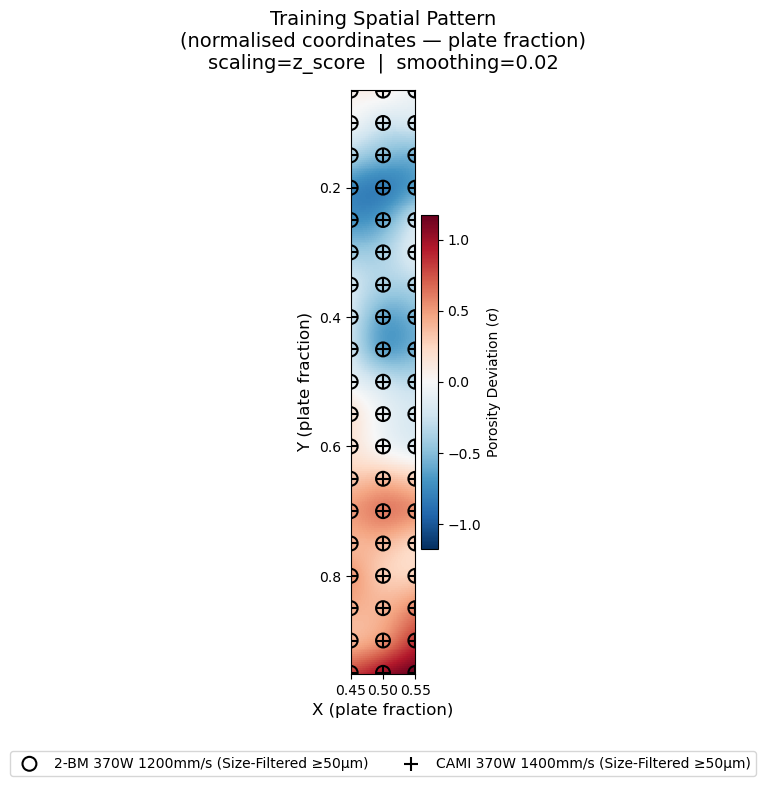

Plotting training pattern (X-homogenized)…
Saved: Y:\Porosity_analysis_all_datasets\porosity_model_training_plots\training_pattern_z_score_smooth0.02_homX.png


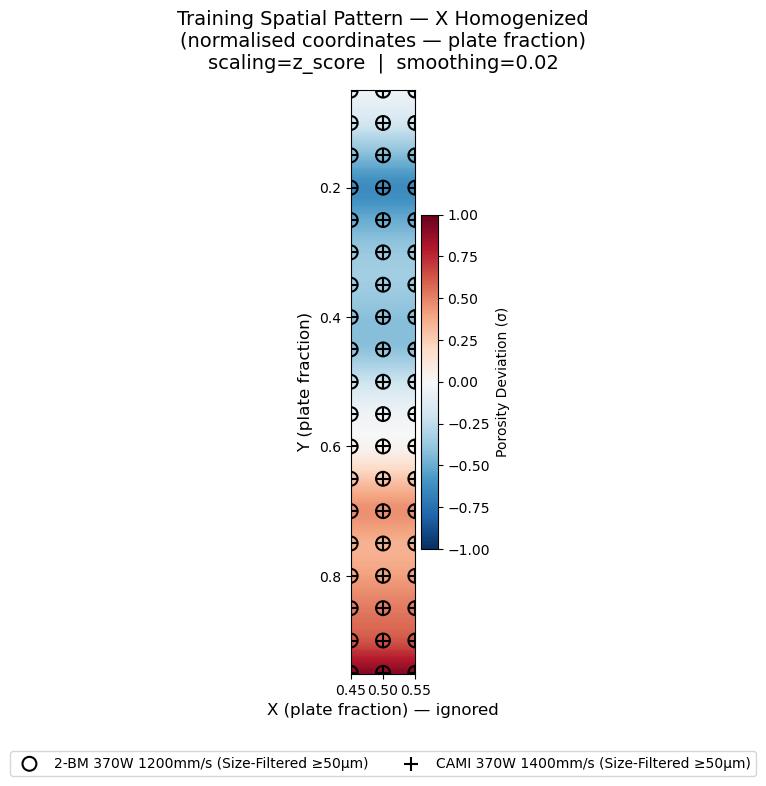

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 2 — Training Dataset Configuration & Model Fit
# ══════════════════════════════════════════════════════════════════════════════

# ── Model hyper-parameters ──────────────────────────────────────────────────
MODEL_SCALING      = 'z_score'   # 'z_score' | 'relative' | 'min_max' | 'absolute'
MODEL_SMOOTHING    = 0.02        # norm-space [0,1]: 0.001–0.01 light, 0.01–0.1 moderate
MODEL_HOMOGENIZE_X = False       # True → X-averaged (row-direction trend only)

TRAINING_SAVE_DIR  = r"Y:\Porosity_analysis_all_datasets\porosity_model_training_plots"

# ── Training datasets ────────────────────────────────────────────────────────
# core_pitch_mm    : centre-to-centre spacing (mm). 4 mm footprint + 2 mm gap = 6 mm.
# plate_width_mm   : physical build plate X dimension (mm). Sample array is centred
#                    within this so the middle column sits at plate_width_mm/2.
# plate_height_mm  : physical build plate Y dimension (mm). Middle row at plate_height_mm/2.

training_datasets = [
    SizeFilteredPorosityDataset(
        title           = "2-BM 370W 1200mm/s (Size-Filtered ≥50µm)",
        base_dir        = r"Y:\Porosity_analysis_all_datasets\2026-02-Narra-1013031\size_filtered_porosity_pcts",
        folder_prefix   = "km_ti64",
        ignore_indices  = {116, 170},
        start_idx       = 58,
        cols            = 3,
        index_pattern   = re.compile(r"KM_Ti64_(\d+)", re.I),
        core_pitch_mm   = 6.0,
        plate_width_mm  = 120.0,
        plate_height_mm = 120.0,
    ),
    SizeFilteredPorosityDataset(
        title           = "CAMI 370W 1400mm/s (Size-Filtered ≥50µm)",
        base_dir        = r"Y:\Porosity_analysis_all_datasets\CT_370W_1400mmps_CAMI\size_filtered_porosity_pcts",
        folder_prefix   = "snt",
        ignore_indices  = {},
        start_idx       = 115,
        cols            = 3,
        index_pattern   = re.compile(r"_Ti_(\d+)_smin"),
        core_pitch_mm   = 6.0,
        plate_width_mm  = 120.0,
        plate_height_mm = 120.0,
    ),
    # ── Add more datasets here ───────────────────────────────────────────────
    # SizeFilteredPorosityDataset(
    #     title           = "Dataset Title",
    #     base_dir        = r"Y:\Porosity_analysis_all_datasets\...\size_filtered_porosity_pcts",
    #     folder_prefix   = "prefix",
    #     ignore_indices  = {},
    #     start_idx       = 0,
    #     cols            = 3,
    #     index_pattern   = re.compile(r"pattern_(\d+)"),
    #     core_pitch_mm   = 6.0,
    #     plate_width_mm  = 120.0,
    #     plate_height_mm = 120.0,
    # ),
]

# ── Build and fit model ──────────────────────────────────────────────────────
model = PorosityPatternModel(
    scaling      = MODEL_SCALING,
    smoothing    = MODEL_SMOOTHING,
    homogenize_x = MODEL_HOMOGENIZE_X,
)
for ds in training_datasets:
    model.add_dataset(ds)
model.fit()

# ── Visualise learned spatial pattern ────────────────────────────────────────
print("\nPlotting training pattern (full 2D)…")
model.plot_training_field(save_dir=TRAINING_SAVE_DIR, homogenize_x=False)

print("Plotting training pattern (X-homogenized)…")
model.plot_training_field(save_dir=TRAINING_SAVE_DIR, homogenize_x=True)

Single-point prediction at (60.0 mm, 30.0 mm) on 120.0×120.0 mm plate:
  predicted local porosity = 0.0170%
  (target mean = 0.0200%  →  ratio = 0.851×)

Grid stats over 120.0 × 120.0 mm plate at 0.5 mm resolution (58081 points):
  min=0.0161%  max=0.0295%  mean=0.0218%


C:\Users\HTU4654\AppData\Local\Temp\ipykernel_49628\164140688.py:302: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  raw = float(self._model_2d(np.array([[x_n, y_n]])))


,x_mm,y_mm,predicted_porosity_pct
count,58081.0000,58081.0000,58081.0000
mean,60.0000,60.0000,0.0218
std,34.7854,34.7854,0.0023
min,0.0000,0.0000,0.0161
25%,30.0000,30.0000,0.0203
50%,60.0000,60.0000,0.0217
75%,90.0000,90.0000,0.0231
max,120.0000,120.0000,0.0295


Plotting predicted field (X-homogenized)…
Saved: Y:\Porosity_analysis_all_datasets\porosity_model_predictions\predicted_120x120mm_mean0.0200_z_score_smooth0.02_homX.png


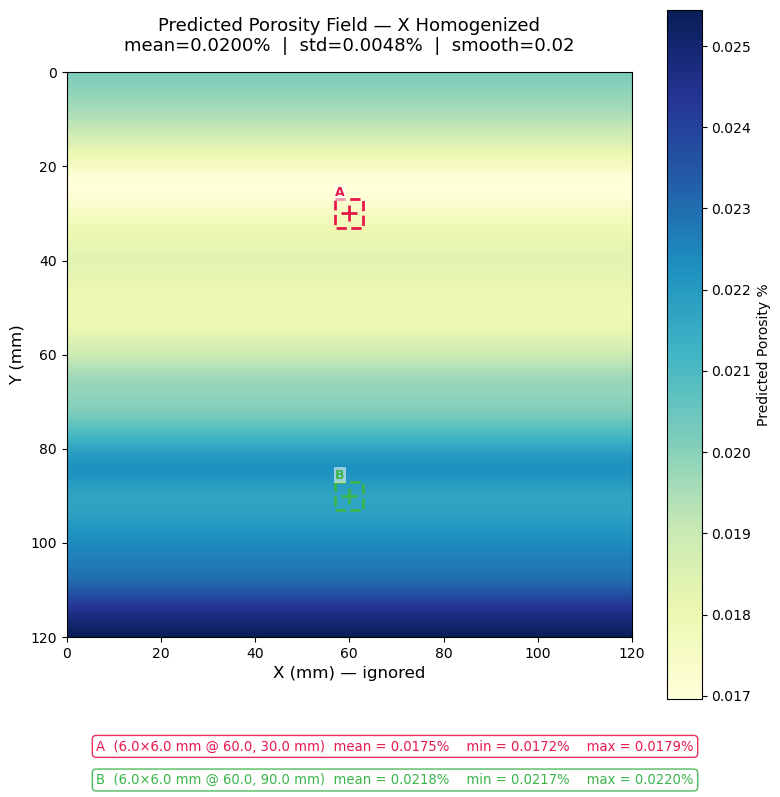

In [29]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 3 — Prediction Interface
#
# Specify the target build plate in mm and sample regions of interest, then run.
# model must be fitted (Cell 2) before running this cell.
# ══════════════════════════════════════════════════════════════════════════════

# ── Target build plate ───────────────────────────────────────────────────────
PLATE_WIDTH_MM  = 120.0   # X dimension of the target build plate (mm)
PLATE_HEIGHT_MM = 120.0   # Y dimension of the target build plate (mm)

# ── Target process parameters ────────────────────────────────────────────────
TARGET_MEAN_POROSITY = 0.02    # expected overall porosity % for the new process
TARGET_STD_POROSITY  = None    # std %; None → pooled training std

# ── Sample regions of interest ───────────────────────────────────────────────
# Each entry: (x_center_mm, y_center_mm, width_mm, height_mm, label)
# width_mm / height_mm default to 6×6 mm if omitted; label defaults to "Region N"
SAMPLE_REGIONS = [
    (60.0, 30.0, 6.0, 6.0, "A"),
    (60.0, 90.0, 6.0, 6.0, "B"),   # uncomment / add more regions as needed
]

# ── Prediction grid resolution ───────────────────────────────────────────────
RESOLUTION_MM = 0.5   # mm between grid points for field plots / DataFrame

# ── Optional label in plot title ─────────────────────────────────────────────
PROCESS_LABEL = ""   # e.g. "New Process: 300W 1600mm/s"

# ── Prediction save directory (None to skip saving) ──────────────────────────
PREDICTION_SAVE_DIR = r"Y:\Porosity_analysis_all_datasets\porosity_model_predictions"

# ═══════════════════════════════════════════════════════════════════════════════
# Single-point prediction (uses first region's centre)
# ═══════════════════════════════════════════════════════════════════════════════
_r0 = SAMPLE_REGIONS[0]
point_pred = model.predict(
    x_mm            = _r0[0],
    y_mm            = _r0[1],
    plate_width_mm  = PLATE_WIDTH_MM,
    plate_height_mm = PLATE_HEIGHT_MM,
    mean_porosity   = TARGET_MEAN_POROSITY,
    std_porosity    = TARGET_STD_POROSITY,
)
print(f"Single-point prediction at ({_r0[0]} mm, {_r0[1]} mm) "
      f"on {PLATE_WIDTH_MM}×{PLATE_HEIGHT_MM} mm plate:")
print(f"  predicted local porosity = {point_pred:.4f}%")
print(f"  (target mean = {TARGET_MEAN_POROSITY:.4f}%"
      f"  →  ratio = {point_pred / TARGET_MEAN_POROSITY:.3f}×)")

# ═══════════════════════════════════════════════════════════════════════════════
# Full plate prediction DataFrame
# ═══════════════════════════════════════════════════════════════════════════════
df_grid = model.predict_grid(
    width_mm      = PLATE_WIDTH_MM,
    height_mm     = PLATE_HEIGHT_MM,
    mean_porosity = TARGET_MEAN_POROSITY,
    std_porosity  = TARGET_STD_POROSITY,
    resolution_mm = RESOLUTION_MM,
)

print(f"\nGrid stats over {PLATE_WIDTH_MM} × {PLATE_HEIGHT_MM} mm plate "
      f"at {RESOLUTION_MM} mm resolution ({len(df_grid)} points):")
print(f"  min={df_grid.predicted_porosity_pct.min():.4f}%"
      f"  max={df_grid.predicted_porosity_pct.max():.4f}%"
      f"  mean={df_grid.predicted_porosity_pct.mean():.4f}%")
display(df_grid.describe().round(4))

# ═══════════════════════════════════════════════════════════════════════════════
# Field plots
# ═══════════════════════════════════════════════════════════════════════════════

# print("\nPlotting predicted field (full 2D)…")
# model.plot_predicted_field(
#     width_mm       = PLATE_WIDTH_MM,
#     height_mm      = PLATE_HEIGHT_MM,
#     mean_porosity  = TARGET_MEAN_POROSITY,
#     std_porosity   = TARGET_STD_POROSITY,
#     resolution_mm  = RESOLUTION_MM,
#     save_dir       = PREDICTION_SAVE_DIR,
#     homogenize_x   = False,
#     sample_regions = SAMPLE_REGIONS,
#     title_extra    = PROCESS_LABEL,
# )

print("Plotting predicted field (X-homogenized)…")
model.plot_predicted_field(
    width_mm       = PLATE_WIDTH_MM,
    height_mm      = PLATE_HEIGHT_MM,
    mean_porosity  = TARGET_MEAN_POROSITY,
    std_porosity   = TARGET_STD_POROSITY,
    resolution_mm  = RESOLUTION_MM,
    save_dir       = PREDICTION_SAVE_DIR,
    homogenize_x   = True,
    sample_regions = SAMPLE_REGIONS,
    title_extra    = PROCESS_LABEL,
)